Saving 133883886687166516.jpg to 133883886687166516.jpg


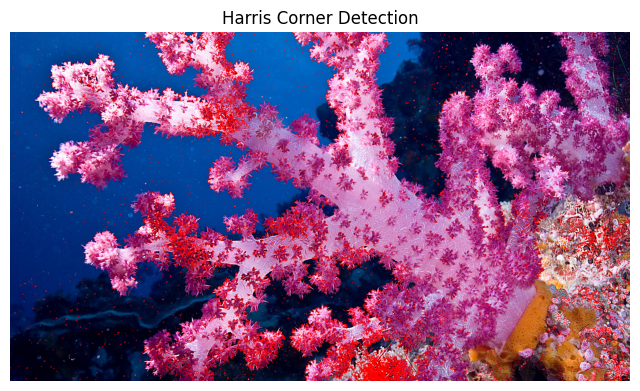

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload an image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read the image
img = cv2.imread(filename)

if img is None:
    print("Error: Image not found!")
else:
    # Convert image to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Convert grayscale image to float32
    gray = np.float32(gray)

    # Apply Harris Corner Detection
    corners = cv2.cornerHarris(gray, 2, 3, 0.04)

    # Dilate the result to mark the corners clearly
    corners = cv2.dilate(corners, None)

    # Mark detected corners in red
    img[corners > 0.01 * corners.max()] = [0, 0, 255]

    # Convert BGR to RGB for display
    result = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Display the result
    plt.figure(figsize=(8, 6))
    plt.imshow(result)
    plt.title("Harris Corner Detection")
    plt.axis("off")
    plt.show()

    # Save and download the output
    cv2.imwrite("harris_corners.jpg", img)
    files.download("harris_corners.jpg")